---
# Part B: Model Implementation

### Step 1: Initialize the code and enable tqdm in pandas

The cell imports the libraries, picks the hardware device, and fixes the random seed so results can be reproduced. `tqdm.pandas()` adds `progress_map()` and `progress_apply()` methods to pandas, so long operations such as tokenization show a progress bar.

In [1]:
import random
import ssl

import certifi
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

# enable tqdm in pandas (adds .progress_map / .progress_apply to Series and DataFrames)
tqdm.pandas()

# use a GPU if one is available: CUDA (NVIDIA) or MPS (Apple Silicon); otherwise the CPU
use_gpu = True
if use_gpu and torch.cuda.is_available():
    device = torch.device('cuda')
elif use_gpu and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print(f'device: {device.type}')

# random seed, so the split, the weight initialization, and dropout are reproducible
seed = 1234
if seed is not None:
    print(f'random seed: {seed}')
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

# NLTK's tokenizer models must be downloaded once. The certifi line avoids an SSL
# certificate error that python.org builds of Python on macOS often raise.
import nltk
ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())
nltk.download('punkt_tab', quiet=True)

device: mps
random seed: 1234


True

### Step 2: The AG's News Topic Classification Dataset

The dataset (Zhang, Zhao & LeCun, 2015) is stored in three files in `data/ag_news_csv/`:

| File | Contents |
|---|---|
| `train.csv` | Training articles: class index, title, description (no header row) |
| `test.csv` | Test articles in the same format |
| `classes.txt` | The class names, one per line. Line *k* is the name of class index *k* (1-based). |

In [2]:
from pathlib import Path

data_dir = Path('data/ag_news_csv')
for f in sorted(data_dir.iterdir()):
    print(f'{f.name:12s} {f.stat().st_size/1e6:7.2f} MB')

labels = data_dir.joinpath('classes.txt').read_text().splitlines()
print('classes:', labels)

classes.txt     0.00 MB
test.csv        1.86 MB
train.csv      29.47 MB
classes: ['World', 'Sports', 'Business', 'Sci/Tech']


### Step 3: Load the training data with pandas and examine it

In [3]:
train_df = pd.read_csv(data_dir / 'train.csv', header=None)
train_df.columns = ['class index', 'title', 'description']

# class indices are 1-based, so subtract 1 to look up the class name in `labels`
train_df.insert(1, 'class', train_df['class index'].map(lambda i: labels[i - 1]))
train_df

,class index,class,title,description
0,3,Business,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli..."
1,3,Business,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...
2,3,Business,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...
3,3,Business,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...
4,3,Business,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco..."
...,...,...,...,...
119995,1,World,Pakistan's Musharraf Says Won't Quit as Army C...,KARACHI (Reuters) - Pakistani President Perve...
119996,2,Sports,Renteria signing a top-shelf deal,Red Sox general manager Theo Epstein acknowled...
119997,2,Sports,Saban not going to Dolphins yet,The Miami Dolphins will put their courtship of...
119998,2,Sports,Today's NFL games,PITTSBURGH at NY GIANTS Time: 1:30 p.m. Line: ...


In [4]:
print(f'rows: {len(train_df):,}   columns: {list(train_df.columns)}')
print(f'missing values:\n{train_df.isna().sum()}\n')
print('examples per class:')
print(train_df['class'].value_counts().sort_index())

# rough length statistics (whitespace-separated words)
title_len = train_df['title'].str.split().str.len()
desc_len = train_df['description'].str.split().str.len()
print(f'\ntitle length:       mean {title_len.mean():.1f} words, max {title_len.max()}')
print(f'description length: mean {desc_len.mean():.1f} words, max {desc_len.max()}')

rows: 120,000   columns: ['class index', 'class', 'title', 'description']


missing values:
class index    0
class          0
title          0
description    0
dtype: int64

examples per class:
class
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64



title length:       mean 6.8 words, max 19
description length: mean 31.1 words, max 173


Matplotlib is building the font cache; this may take a moment.


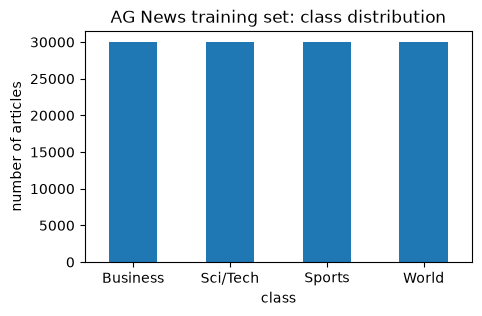

[World] Venezuelans Vote Early in Referendum on Chavez Rule (Reuters)
    Reuters - Venezuelans turned out early\and in large numbers on Sunday to vote in a historic referendum\that will either remove left-wing President Hugo Chavez from\office or give him a new mandate to govern for the next two\years.

[Sports] Phelps, Thorpe Advance in 200 Freestyle (AP)
    AP - Michael Phelps took care of qualifying for the Olympic 200-meter freestyle semifinals Sunday, and then found out he had been added to the American team for the evening's 400 freestyle relay final. Phelps' rivals Ian Thorpe and Pieter van den Hoogenband and teammate Klete Keller were faster than the teenager in the 200 free preliminaries.

[Business] Wall St. Bears Claw Back Into the Black (Reuters)
    Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.

[Sci/Tech] 'Madden,' 'ESPN' Football Score in Different Ways (Reuters)
    Reuters - Was absenteeism a little high\on Tuesday amo

In [5]:
import matplotlib.pyplot as plt

ax = train_df['class'].value_counts().sort_index().plot.bar(rot=0, figsize=(5, 3))
ax.set_ylabel('number of articles')
ax.set_title('AG News training set: class distribution')
plt.show()

# one example per class
for c in labels:
    row = train_df[train_df['class'] == c].iloc[0]
    print(f'[{c}] {row.title}\n    {row.description}\n')

### Step 4: Replace backslashes with spaces

Some descriptions contain a stray backslash where the original article had a line break, for example in *"Wall Street's dwindling\band of ultra-cynics"*. If left in place, the tokenizer would treat `dwindling\band` as a single, meaningless token. The title and description are joined and lowercased into one `text` column, and every backslash is replaced with a space using pandas' `str.replace`.

In [6]:
print('before:', train_df.loc[0, 'description'])

train_df['text'] = train_df['title'].str.lower() + ' ' + train_df['description'].str.lower()
train_df['text'] = train_df['text'].str.replace('\\', ' ', regex=False)

print('after: ', train_df.loc[0, 'text'])
print('rows still containing a backslash:', train_df['text'].str.contains('\\', regex=False).sum())

before: Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.
after:  wall st. bears claw back into the black (reuters) reuters - short-sellers, wall street's dwindling band of ultra-cynics, are seeing green again.
rows still containing a backslash: 0


### Step 5: Tokenize with NLTK's `word_tokenize()` and add a `tokens` column

In [7]:
from nltk.tokenize import word_tokenize

train_df['tokens'] = train_df['text'].progress_map(word_tokenize)
train_df[['class', 'text', 'tokens']].head()

  0%|          | 0/120000 [00:00<?, ?it/s]

,class,text,tokens
0,Business,wall st. bears claw back into the black (reute...,"[wall, st., bears, claw, back, into, the, blac..."
1,Business,carlyle looks toward commercial aerospace (reu...,"[carlyle, looks, toward, commercial, aerospace..."
2,Business,oil and economy cloud stocks' outlook (reuters...,"[oil, and, economy, cloud, stocks, ', outlook,..."
3,Business,iraq halts oil exports from main southern pipe...,"[iraq, halts, oil, exports, from, main, southe..."
4,Business,"oil prices soar to all-time record, posing new...","[oil, prices, soar, to, all-time, record, ,, p..."


In [8]:
from sklearn.model_selection import train_test_split

# hold out 20% of the training file as a development (validation) set
train_df, dev_df = train_test_split(train_df, train_size=0.8, random_state=seed)
train_df = train_df.reset_index(drop=True)
dev_df = dev_df.reset_index(drop=True)

print(f'train rows: {len(train_df):,}')
print(f'dev rows:   {len(dev_df):,}')

train rows: 96,000
dev rows:   24,000


### Step 6: Create the vocabulary from the training data

Only tokens that appear **more than 10 times** in the training split are kept. Index 0 is reserved for `[UNK]`. Each document is then turned into a sparse bag-of-words vector of counts.

In [9]:
threshold = 10
token_counts = train_df['tokens'].explode().value_counts()
total_types = len(token_counts)
token_counts = token_counts[token_counts > threshold]

id_to_token = ['[UNK]'] + token_counts.index.tolist()
token_to_id = {w: i for i, w in enumerate(id_to_token)}
vocabulary_size = len(id_to_token)

print(f'distinct tokens in training split: {total_types:,}')
print(f'vocabulary size (count > {threshold}, plus [UNK]): {vocabulary_size:,}')
print('most frequent tokens:', id_to_token[1:21])

distinct tokens in training split: 79,913
vocabulary size (count > 10, plus [UNK]): 17,456
most frequent tokens: ['the', ',', '.', 'to', 'a', 'of', 'in', ';', 'and', 'on', 'for', '#', '39', '(', ')', '-', 's', 'that', 'with', '&']


In [10]:
from collections import defaultdict

def make_feature_vector(tokens, unk_id=0):
    '''Sparse bag-of-words: {token id: count}. Out-of-vocabulary tokens map to [UNK].'''
    vector = defaultdict(int)
    for t in tokens:
        i = token_to_id.get(t, unk_id)
        vector[i] += 1
    return vector

train_df['features'] = train_df['tokens'].progress_map(make_feature_vector)
dev_df['features'] = dev_df['tokens'].progress_map(make_feature_vector)

# show the bag-of-words of the first training example in readable form
ex = train_df.loc[0]
print(ex['text'])
print({id_to_token[k]: v for k, v in sorted(ex['features'].items(), key=lambda kv: -kv[1])})

  0%|          | 0/96000 [00:00<?, ?it/s]

  0%|          | 0/24000 [00:00<?, ?it/s]

najaf's residents feel trapped in battle (ap) ap - for nearly three weeks, amer al-jamali hasn't been able to go to work. he cannot visit his father, find medication for his diabetic children or even sleep on his roof to escape the city's suffocating heat made worse by power outages.
{'[UNK]': 4, 'to': 3, 'his': 3, "'s": 2, 'ap': 2, 'for': 2, ',': 2, '.': 2, 'najaf': 1, 'residents': 1, 'feel': 1, 'trapped': 1, 'in': 1, 'battle': 1, '(': 1, ')': 1, '-': 1, 'nearly': 1, 'three': 1, 'weeks': 1, 'has': 1, "n't": 1, 'been': 1, 'able': 1, 'go': 1, 'work': 1, 'he': 1, 'can': 1, 'not': 1, 'visit': 1, 'father': 1, 'find': 1, 'medication': 1, 'children': 1, 'or': 1, 'even': 1, 'sleep': 1, 'on': 1, 'roof': 1, 'escape': 1, 'the': 1, 'city': 1, 'heat': 1, 'made': 1, 'worse': 1, 'by': 1, 'power': 1, 'outages': 1}


### Step 7: Initialize the model, loss function, optimizer, and data loader

The three pieces are defined in order:

1. A PyTorch `Dataset` that expands each sparse dictionary into a dense vector of length |V| when an example is requested.
2. The feed-forward `Model`.
3. The hyperparameters, loss function, optimizer, and data loaders.

In [11]:
from torch.utils.data import Dataset

class MyDataset(Dataset):
    def __init__(self, x, y):
        self.x = x.reset_index(drop=True)   # sparse feature dicts
        self.y = y.reset_index(drop=True)   # 0-based class ids

    def __len__(self):
        return len(self.x)

    def __getitem__(self, index):
        x = torch.zeros(vocabulary_size, dtype=torch.float32)
        for k, v in self.x[index].items():
            x[k] = v
        y = torch.tensor(self.y[index])
        return x, y

In [12]:
from torch import nn

class Model(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Dropout(dropout),                 # drop input word counts
            nn.Linear(input_dim, hidden_dim),    # |V| -> hidden
            nn.ReLU(),                           # non-linearity
            nn.Dropout(dropout),                 # drop hidden units
            nn.Linear(hidden_dim, output_dim),   # hidden -> one logit per class
        )

    def forward(self, x):
        return self.layers(x)

In [13]:
from torch import optim
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score

# hyperparameters
lr = 1e-3
weight_decay = 1e-5
batch_size = 500
shuffle = True
n_epochs = 5
input_dim = vocabulary_size
hidden_dim = 50
output_dim = len(labels)
dropout = 0.3

# initialize the model, loss function, optimizer, and data loaders
model = Model(input_dim, hidden_dim, output_dim, dropout).to(device)
loss_func = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

train_ds = MyDataset(train_df['features'], train_df['class index'] - 1)
train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=shuffle)
dev_ds = MyDataset(dev_df['features'], dev_df['class index'] - 1)
dev_dl = DataLoader(dev_ds, batch_size=batch_size, shuffle=False)

# lists used to store plotting data
train_loss, train_acc = [], []
dev_loss, dev_acc = [], []

print(model)
n_params = sum(p.numel() for p in model.parameters())
print(f'trainable parameters: {n_params:,}')
print(f'batches per epoch: train {len(train_dl)}, dev {len(dev_dl)}')

Model(
  (layers): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=17456, out_features=50, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=50, out_features=4, bias=True)
  )
)
trainable parameters: 873,054
batches per epoch: train 192, dev 48


### Step 8: Train the model

In [14]:
import time

start = time.time()
for epoch in range(n_epochs):
    losses, acc = [], []
    # training mode: dropout is active
    model.train()
    for X, y_true in tqdm(train_dl, desc=f'epoch {epoch+1} (train)', leave=False):
        model.zero_grad()                       # clear gradients from the previous step
        X, y_true = X.to(device), y_true.to(device)
        y_pred = model(X)                       # forward pass: logits
        loss = loss_func(y_pred, y_true)        # cross-entropy loss
        gold = y_true.detach().cpu().numpy()
        pred = np.argmax(y_pred.detach().cpu().numpy(), axis=1)
        losses.append(loss.detach().cpu().item())
        acc.append(accuracy_score(gold, pred))
        loss.backward()                         # back-propagation
        optimizer.step()                        # Adam parameter update
    train_loss.append(np.mean(losses))
    train_acc.append(np.mean(acc))

    # evaluation mode: dropout off, no gradients
    model.eval()
    with torch.no_grad():
        losses, acc = [], []
        for X, y_true in tqdm(dev_dl, desc=f'epoch {epoch+1} (dev)', leave=False):
            X, y_true = X.to(device), y_true.to(device)
            y_pred = model(X)
            loss = loss_func(y_pred, y_true)
            gold = y_true.cpu().numpy()
            pred = np.argmax(y_pred.cpu().numpy(), axis=1)
            losses.append(loss.cpu().item())
            acc.append(accuracy_score(gold, pred))
        dev_loss.append(np.mean(losses))
        dev_acc.append(np.mean(acc))

    print(f'epoch {epoch+1}: train loss {train_loss[-1]:.4f} acc {train_acc[-1]:.4f} | '
          f'dev loss {dev_loss[-1]:.4f} acc {dev_acc[-1]:.4f}')
print(f'training time: {time.time() - start:.0f} s')

epoch 1 (train):   0%|          | 0/192 [00:00<?, ?it/s]

epoch 1 (dev):   0%|          | 0/48 [00:00<?, ?it/s]

epoch 1: train loss 0.5807 acc 0.8340 | dev loss 0.2860 acc 0.9142


epoch 2 (train):   0%|          | 0/192 [00:00<?, ?it/s]

epoch 2 (dev):   0%|          | 0/48 [00:00<?, ?it/s]

...

epoch 4 (dev):   0%|          | 0/48 [00:00<?, ?it/s]

epoch 4: train loss 0.2343 acc 0.9210 | dev loss 0.2252 acc 0.9229


epoch 5 (train):   0%|          | 0/192 [00:00<?, ?it/s]

epoch 5 (dev):   0%|          | 0/48 [00:00<?, ?it/s]

epoch 5: train loss 0.2173 acc 0.9258 | dev loss 0.2226 acc 0.9238
training time: 60 s


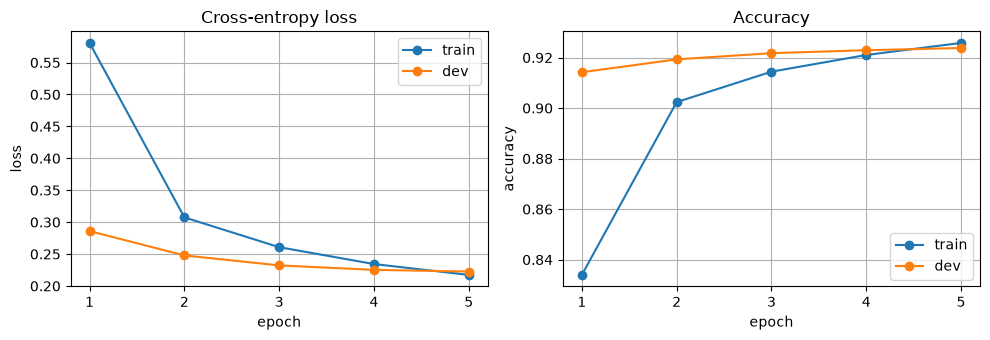

In [15]:
x = np.arange(n_epochs) + 1
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(x, train_loss, marker='o', label='train')
axes[0].plot(x, dev_loss, marker='o', label='dev')
axes[0].set(xlabel='epoch', ylabel='loss', title='Cross-entropy loss')
axes[1].plot(x, train_acc, marker='o', label='train')
axes[1].plot(x, dev_acc, marker='o', label='dev')
axes[1].set(xlabel='epoch', ylabel='accuracy', title='Accuracy')
for ax in axes:
    ax.grid(True); ax.legend(); ax.set_xticks(x)
plt.tight_layout()
plt.show()

### Step 9: Evaluate the model on the test dataset

The test set goes through **exactly the same preprocessing** as the training data: lowercasing, backslash replacement, tokenization, and BoW features built with the *training* vocabulary. The test set is never used for training or for choosing settings.

In [16]:
test_df = pd.read_csv(data_dir / 'test.csv', header=None)
test_df.columns = ['class index', 'title', 'description']
test_df['text'] = test_df['title'].str.lower() + ' ' + test_df['description'].str.lower()
test_df['text'] = test_df['text'].str.replace('\\', ' ', regex=False)
test_df['tokens'] = test_df['text'].progress_map(word_tokenize)
test_df['features'] = test_df['tokens'].progress_map(make_feature_vector)

print(f'test rows: {len(test_df):,}')
print(test_df['class index'].map(lambda i: labels[i - 1]).value_counts().sort_index())
oov = test_df['features'].map(lambda d: d.get(0, 0)).sum() / test_df['tokens'].map(len).sum()
print(f'share of test tokens that are [UNK]: {oov:.2%}')

  0%|          | 0/7600 [00:00<?, ?it/s]

  0%|          | 0/7600 [00:00<?, ?it/s]

test rows: 7,600
class index
Business    1900
Sci/Tech    1900
Sports      1900
World       1900
Name: count, dtype: int64
share of test tokens that are [UNK]: 3.93%


In [17]:
from sklearn.metrics import classification_report

model.eval()
test_ds = MyDataset(test_df['features'], test_df['class index'] - 1)
test_dl = DataLoader(test_ds, batch_size=batch_size)
y_pred = []

with torch.no_grad():
    for X, _ in tqdm(test_dl, leave=False):
        X = X.to(device)
        y = torch.argmax(model(X), dim=1)     # one predicted class per example
        y_pred.append(y.cpu().numpy())

y_true = test_ds.y.to_numpy()
y_pred = np.concatenate(y_pred)
print(f'test accuracy: {accuracy_score(y_true, y_pred):.4f}\n')
print(classification_report(y_true, y_pred, target_names=labels, digits=3))

  0%|          | 0/16 [00:00<?, ?it/s]

test accuracy: 0.9224

              precision    recall  f1-score   support

       World      0.950     0.902     0.925      1900
      Sports      0.963     0.987     0.975      1900
    Business      0.894     0.886     0.890      1900
    Sci/Tech      0.884     0.914     0.899      1900

    accuracy                          0.922      7600
   macro avg      0.923     0.922     0.922      7600
weighted avg      0.923     0.922     0.922      7600



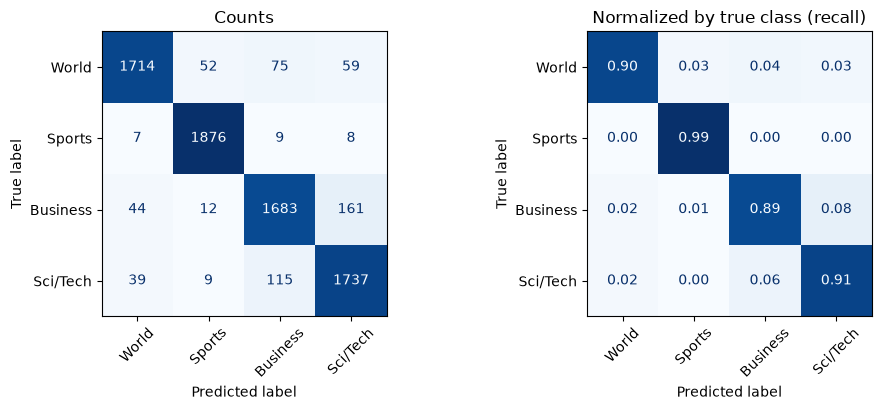

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, norm, fmt, title in [(axes[0], None, 'd', 'Counts'),
                             (axes[1], 'true', '.2f', 'Normalized by true class (recall)')]:
    cm = confusion_matrix(y_true, y_pred, normalize=norm)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(
        cmap='Blues', values_format=fmt, colorbar=False, ax=ax, xticks_rotation=45)
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [19]:
# a few misclassified test examples, to see what kinds of errors the model makes
test_df['pred'] = [labels[i] for i in y_pred]
test_df['gold'] = [labels[i] for i in y_true]
errors = test_df[test_df['pred'] != test_df['gold']]
print(f'misclassified: {len(errors):,} of {len(test_df):,}\n')
for _, r in errors.sample(8, random_state=seed).iterrows():
    print(f'gold={r.gold:9s} pred={r.pred:9s} | {r.title}')

misclassified: 590 of 7,600

gold=World     pred=Sci/Tech  | Mars water tops science honours
gold=World     pred=Business  | A Founding Father?
gold=Business  pred=Sci/Tech  | Nintendo to Unveil Handheld Upgrade
gold=Sci/Tech  pred=Sports    | The Bahamas - the real medal winner of the Athens Olympics
gold=Business  pred=Sci/Tech  | Broadband charges set to tumble
gold=Business  pred=Sports    | No ticket matched all four numbers and the MegaBall in Friday #39;s &lt;b&gt;...&lt;/b&gt;
gold=Sci/Tech  pred=Business  | TiVo loss widens
gold=World     pred=Sports    | Spanish teenager pleads guilty in first trial stemming from Madrid &lt;b&gt;...&lt;/b&gt;
